In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
import os
import sys

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *
from GLOBAL.mcmc import *

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

# Reference Field

In [3]:
alpha1_min = 0.1 * ALPHA1
alpha1_max = 2 * ALPHA1
alpha2_min = 0.1 * ALPHA2
alpha2_max = 2 * ALPHA2

resolution = 40

alpha1_grid = np.linspace(alpha1_min, alpha1_max, resolution)
alpha2_grid = np.linspace(alpha2_min, alpha2_max, resolution)

ALPHA1_GRID, ALPHA2_GRID = np.meshgrid(alpha1_grid, alpha2_grid)
shape_chunk = ALPHA1_GRID.shape
ALPHA1_GRID = ALPHA1_GRID.flatten()
ALPHA2_GRID = ALPHA2_GRID.flatten()

params = np.stack((ALPHA1_GRID, ALPHA2_GRID), axis=1)
max_angle = 1000000 * np.pi / 180

logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                   PE, DT, DR, FORCE_STRENGTH,
                                   params, torque_limit=max_angle,
                                   n_particles=10
                                   )
logl = logl.reshape(shape_chunk)
extent=(alpha1_min, alpha1_max, alpha2_min, alpha2_max)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


# Markov Chain

In [4]:
ALPHA1_CHAIN, ALPHA2_CHAIN = mcmc(x_data, y_data, alpha_mutations=[1e-0, 1e-0], n_samples=100, superstep=1)

Acceptance: 37%. Progress


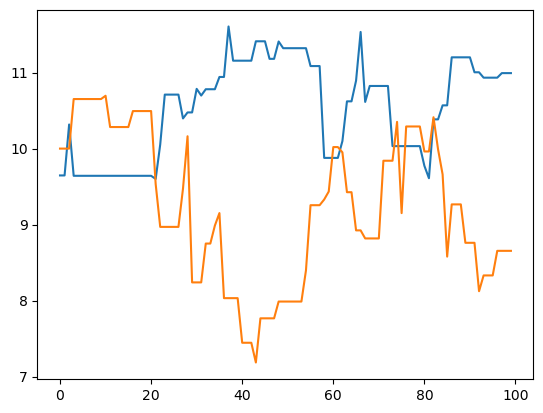

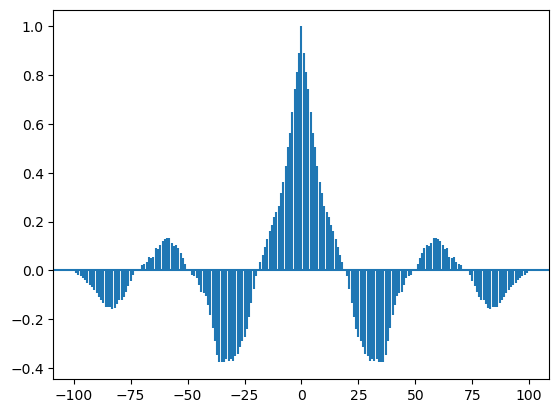

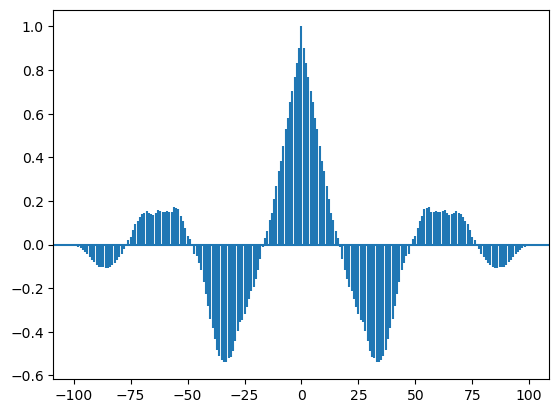

In [7]:
plt.plot(ALPHA1_CHAIN)
plt.plot(ALPHA2_CHAIN)
plt.show()
# Plot autocorr of the two chains
lag = len(ALPHA1_CHAIN) - 1
plt.acorr(ALPHA1_CHAIN - np.mean(ALPHA1_CHAIN), maxlags=lag, normed=True)
plt.show()
plt.acorr(ALPHA2_CHAIN - np.mean(ALPHA2_CHAIN), maxlags=lag, normed=True)
plt.show()

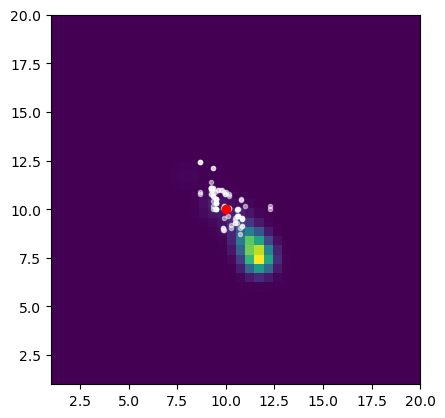

In [ ]:
particle_P_gamma = 1
cmap = 'viridis' if particle_P_gamma == 1 else 'magma_r'
P = np.exp((logl - np.max(logl))/particle_P_gamma)
P /= np.sum(P)
P = gaussian_filter(P, 1)
plt.imshow(P, extent=extent, origin='lower', cmap=cmap)
plt.plot(ALPHA1_CHAIN, ALPHA2_CHAIN, '.w', alpha=0.5)
plt.plot([ALPHA1], [ALPHA2], 'or')

# Posterior Predictive Torque

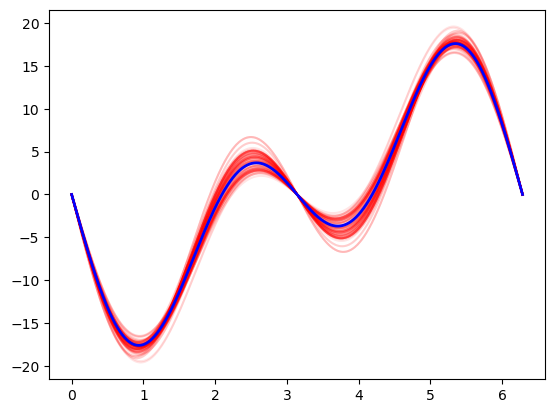

In [ ]:
phi = np.linspace(0, 2*np.pi, 1000)

for a1, a2 in zip(ALPHA1_CHAIN, ALPHA2_CHAIN):
    torque = TORQUE(phi, [a1, a2])
    plt.plot(phi, torque, 'r', alpha=0.1)

torque_true = TORQUE(phi, [ALPHA1, ALPHA2])
plt.plot(phi, torque_true, 'b', lw=2)

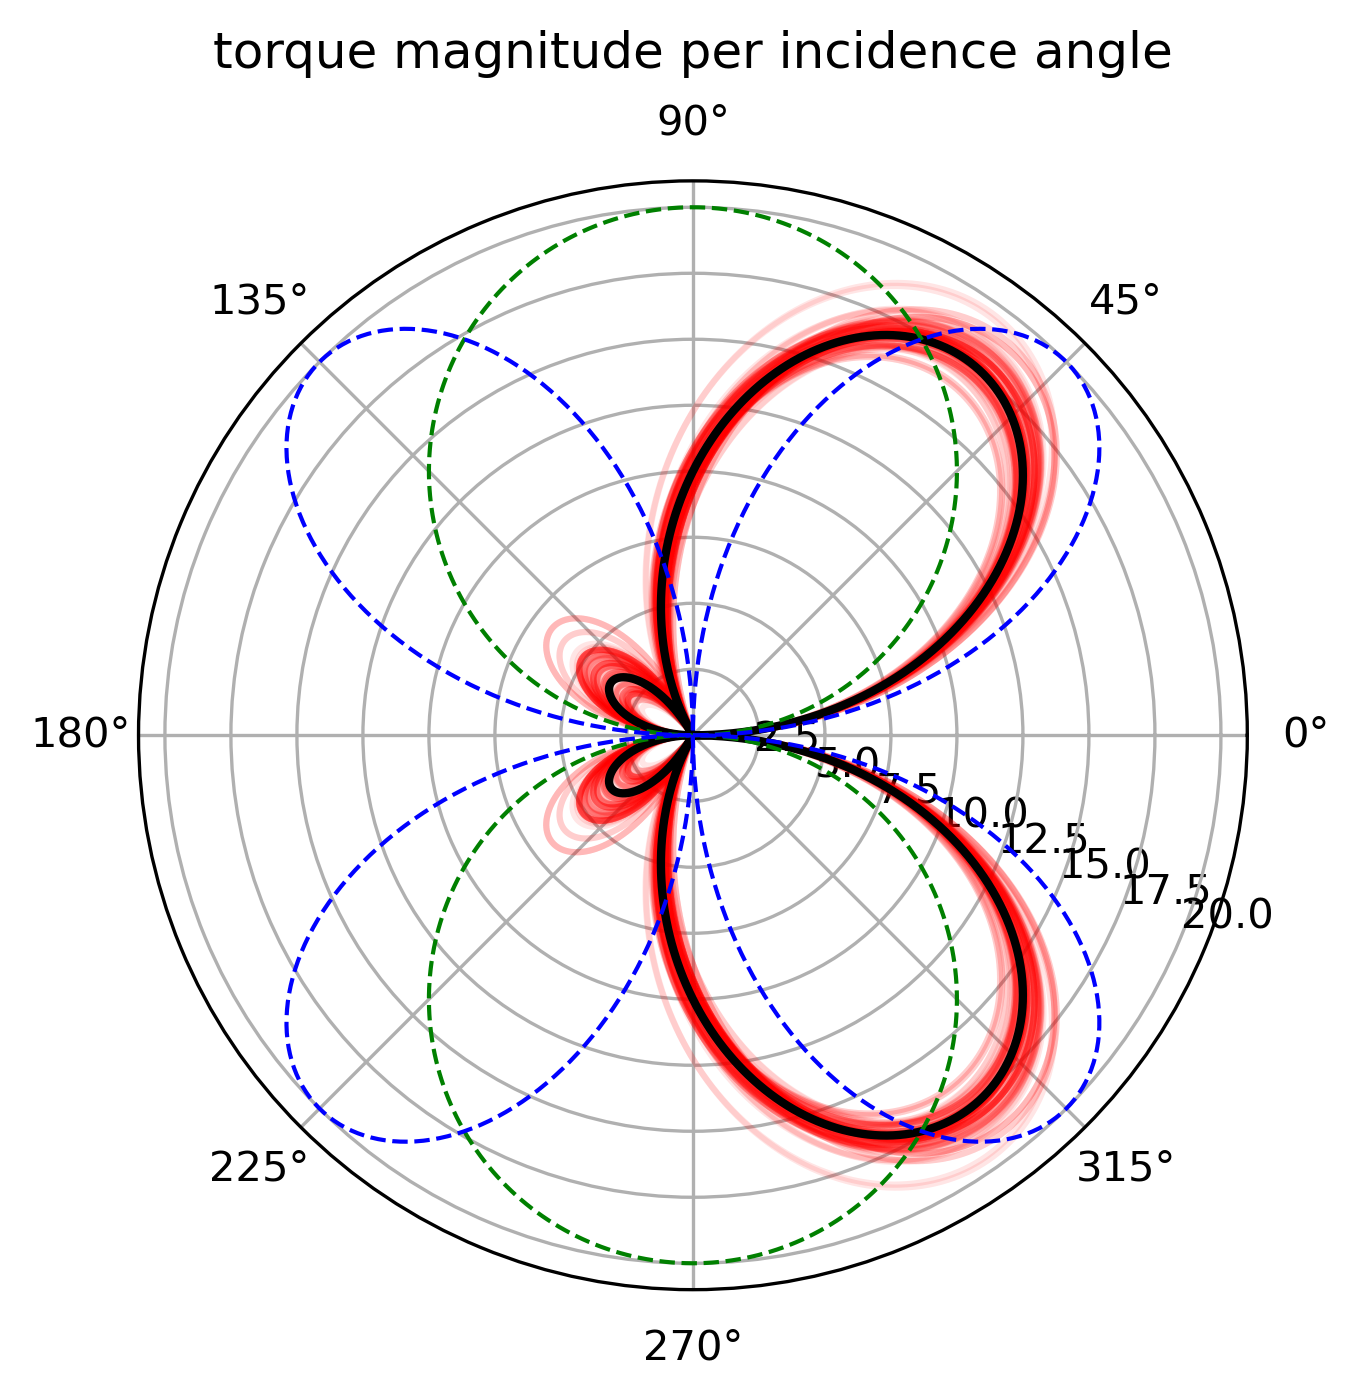

In [ ]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, dpi=300)

for a1, a2 in zip(ALPHA1_CHAIN, ALPHA2_CHAIN):
    torque = np.abs(TORQUE(phi, [a1, a2]))
    plt.plot(phi, torque, 'r', alpha=0.1)
torque_true = np.abs(TORQUE(phi, [ALPHA1, ALPHA2]))
plt.plot(phi, torque_true, 'k', lw=2)

torque_perp = np.abs(TORQUE(phi, [2*ALPHA1, 0.]))
plt.plot(phi, torque_perp, 'g', lw=1, ls='--')

torque_tang = np.abs(TORQUE(phi, [0., 2*ALPHA2]))
plt.plot(phi, torque_tang, 'b', lw=1, ls='--')

ax.set_rlabel_position(-22.5)  # Move radial labels away from plotted line
ax.grid(True)

ax.set_title("torque magnitude per incidence angle", va='bottom')
plt.show()